# Atlas: market shock and synthetic interbank contagion

A reproducible demonstration of credit risk and systemic stress. Run all cells in order. The S&P 500 observations are historical; the banks, exposures, impairments and defaults are **synthetic scenarios**, not historical bank failures or forecasts. The shock multiplier is an assumption, not an estimated relationship. See `docs/MODELS.md` and `docs/DATA_PROVENANCE.md`.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from atlas.generate import generate
from atlas.models import Scenario
from atlas.engine import bank_risk, credit_risk, furfine, debt_rank, monte_carlo
from atlas.market import market_data, calibration
from atlas.storage import dataset_hash
pd.set_option("display.max_columns", 20)


## 1. Generate and validate a synthetic system
The lender-to-borrower edges are assets for lenders and liabilities for borrowers. The dataset validator reconciles both sides and every bank balance sheet. Seed 42 makes the example repeatable.


In [2]:
data = generate(50, 42, "core_periphery")
print("Banks:", len(data.banks), "Loans:", len(data.exposures), "SHA-256:", dataset_hash(data))
banks = bank_risk(data)
banks[["id", "tier", "total_assets", "equity", "equity_ratio", "expected_loss"]].head()


Banks: 50 Loans: 222 SHA-256: c6948be98fa2a18832d103bc4efca83d2c7f33a7ff2842b6a7cc98b26df623fb


,id,tier,total_assets,equity,equity_ratio,expected_loss
0,B001,core,853.056172,83.386631,0.097750,2.342678
1,B002,core,978.396441,97.916602,0.100079,4.156443
2,B003,core,860.962443,107.987786,0.125427,2.609704
3,B004,core,1230.756083,107.457658,0.087310,4.199600
4,B005,core,1111.676398,142.619248,0.128292,4.343611


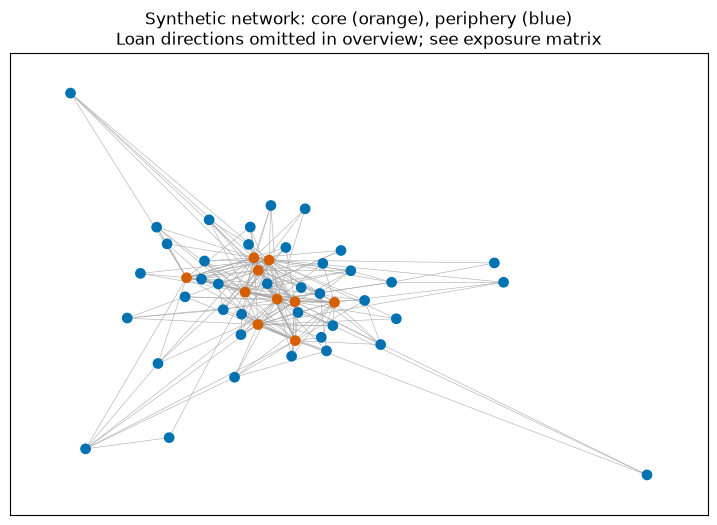

In [3]:
g = nx.DiGraph()
g.add_nodes_from((b.id, {"tier": b.tier}) for b in data.banks)
g.add_weighted_edges_from((e.lender, e.borrower, e.amount) for e in data.exposures)
pos = nx.spring_layout(g, seed=42, weight=None, k=0.6, iterations=150)
fig, ax = plt.subplots(figsize=(9, 6))
nx.draw_networkx(g, pos, ax=ax, node_size=45, node_color=["#d55e00" if g.nodes[n]["tier"] == "core" else "#0072b2" for n in g], edge_color="#aaaaaa", width=.4, arrows=False, with_labels=False)
ax.set_title("Synthetic network: core (orange), periphery (blue)\nLoan directions omitted in overview; see exposure matrix");


## 2. Credit risk
One-period expected loss is `PD × LGD × EAD`; PD belongs to the borrower, LGD is one minus assumed recovery, and EAD is the loan amount. These are illustrative inputs, not calibrated regulatory estimates.


In [4]:
loans = credit_risk(data, recovery=0.4)
print(f"Total expected credit loss: {loans.expected_loss.sum():,.2f} synthetic INR crore")
loans.sort_values("expected_loss", ascending=False).head()


Total expected credit loss: 61.81 synthetic INR crore


,lender,borrower,ead,pd,lgd,expected_loss
119,B009,B032,39.844435,0.02,0.6,0.478133
200,B042,B002,39.758460,0.02,0.6,0.477102
96,B008,B007,38.947616,0.02,0.6,0.467371
171,B027,B004,38.585869,0.02,0.6,0.463030
40,B004,B015,38.568362,0.02,0.6,0.462820


## 3. Observed COVID-period market drawdown
The packaged FRED S&P 500 daily closing series spans February–April 2020, excluding missing observations. The selected-window maximum drawdown is mapped to an external-asset impairment by `min(1, drawdown magnitude × multiplier)`. This is an exogenous scenario design choice: equity index prices cannot identify interbank exposures or contagion.


{'series': 'SP500', 'source': 'https://fred.stlouisfed.org/series/SP500', 'window_start': '2020-02-03', 'window_end': '2020-04-30', 'peak_date': '2020-02-19', 'trough_date': '2020-03-23', 'drawdown_magnitude': 0.3392495902426059, 'multiplier': 0.3, 'external_impairment': 0.10177487707278178, 'mapping': 'min(1, selected-window maximum drawdown magnitude * multiplier)'}


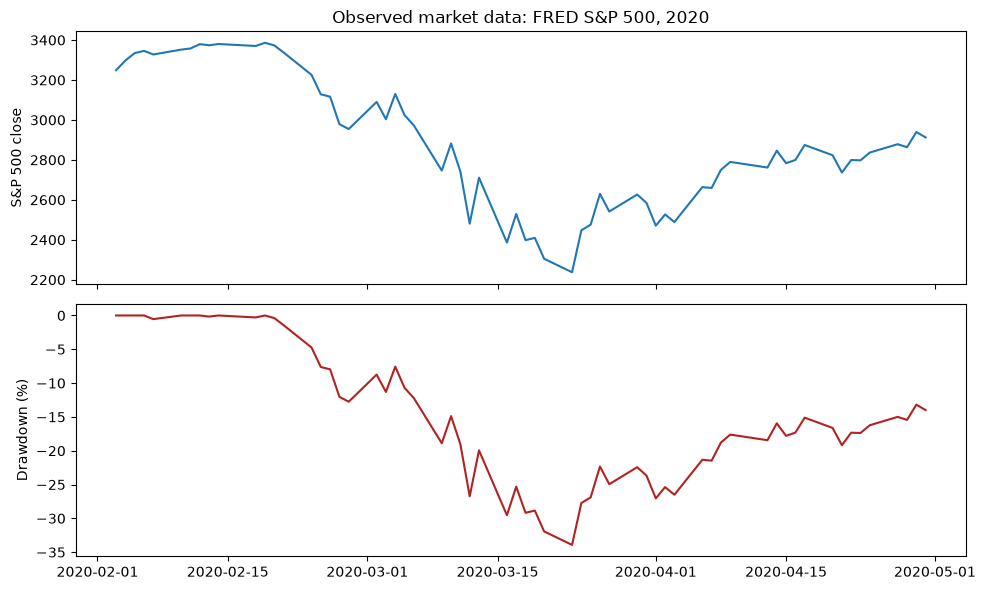

In [5]:
market = market_data()
cal = calibration(multiplier=0.3)
print(cal)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(market.date, market.close); axes[0].set_ylabel("S&P 500 close")
axes[1].plot(market.date, 100 * market.drawdown, color="firebrick"); axes[1].set_ylabel("Drawdown (%)")
axes[0].set_title("Observed market data: FRED S&P 500, 2020"); fig.tight_layout()


## 4. Furfine-style cascade
Apply the illustrative impairment once to external assets, then propagate fixed-recovery loan losses synchronously from newly defaulted borrowers to surviving lenders. Rounds are computational steps, not dates; losses exclude claims held by already failed lenders.


In [6]:
scenario = Scenario(name="Illustrative COVID-market mapping", recovery=0.4, external_impairment=cal["external_impairment"])
result = furfine(data, scenario)
print("Initial defaults:", len(result["initial_defaults"]), "Secondary:", len(result["secondary_defaults"]), "Total:", result["default_count"])
rounds = pd.DataFrame([{ "round": r["round"], "new_defaults": len(r["new_defaults"]), "cumulative_defaults": r["cumulative_defaults"], "interbank_loss": r["interbank_loss"]} for r in result["rounds"]])
rounds


Initial defaults: 14 Secondary: 31 Total: 45


,round,new_defaults,cumulative_defaults,interbank_loss
0,0,14,14,0.000000
1,1,7,21,517.354332
2,2,17,38,624.287484
3,3,7,45,198.302314
4,4,0,45,0.000000


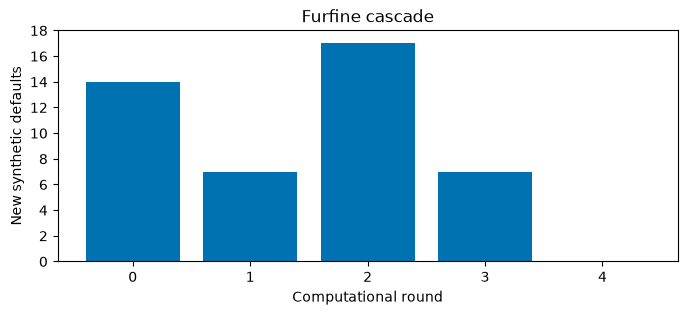

In [7]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(rounds["round"], rounds["new_defaults"], color="#0072b2")
ax.set(xlabel="Computational round", ylabel="New synthetic defaults", title="Furfine cascade")
ax.set_yticks(range(0, int(rounds.new_defaults.max()) + 2, 2));


## 5. Sensitivity and exploratory models
The same starting balance sheets are used for each multiplier. DebtRank is an exploratory distress measure, not a default count. Monte Carlo samples independent assumed defaults; it is conditional on the selected shock and does not model correlated default risk.


In [8]:
rows = []
for multiplier in [0.0, 0.1, 0.2, 0.3, 0.4]:
    c = calibration(multiplier=multiplier)
    r = furfine(data, Scenario(external_impairment=c["external_impairment"], recovery=0.4))
    rows.append({"multiplier": multiplier, "impairment": c["external_impairment"], "initial": len(r["initial_defaults"]), "secondary": len(r["secondary_defaults"]), "total": r["default_count"]})
sensitivity = pd.DataFrame(rows)
sensitivity


,multiplier,impairment,initial,secondary,total
0,0.0,0.000000,0,0,0
1,0.1,0.033925,0,0,0
2,0.2,0.067850,2,0,2
3,0.3,0.101775,14,31,45
4,0.4,0.135700,29,21,50


In [9]:
print("Incremental DebtRank:", debt_rank(data, scenario.external_impairment, scenario.recovery)["incremental_debtrank"])
mc = monte_carlo(data, scenario, trials=200, seed=42)
print("Independent-default Monte Carlo summary:")
mc[["defaults", "secondary_defaults", "interbank_loss"]].describe()


Incremental DebtRank: 0.19805946312090228
Independent-default Monte Carlo summary:


,defaults,secondary_defaults,interbank_loss
count,200.000000,200.000000,200.000000
mean,45.125000,30.430000,1334.420303
std,0.331549,0.740162,28.131909
min,45.000000,28.000000,1236.965802
25%,45.000000,30.000000,1327.290283
50%,45.000000,31.000000,1339.944131
75%,45.000000,31.000000,1339.944131
max,46.000000,31.000000,1428.316379


## 6. API demonstration
The same calculations are available from FastAPI; this in-process client checks the actual HTTP contract without starting a server. For interactive API documentation run `uv run uvicorn atlas.api:app --host 127.0.0.1 --port 8000` and visit `/docs`.


In [10]:
from fastapi.testclient import TestClient
from atlas.api import app
client = TestClient(app)
response = client.post("/simulate", json={"dataset": data.model_dump(mode="json"), "scenario": scenario.model_dump(mode="json")})
response.raise_for_status()
assert response.json()["default_count"] == result["default_count"]
print("API status:", response.status_code, "Synthetic defaults:", response.json()["default_count"])


API status: 200 Synthetic defaults: 45


<repository>/.venv/lib/python3.12/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


## Interpretation
The historical drawdown is observed; the inferred shock, network and defaults are illustrative. Results depend on the assumed multiplier, recovery, synthetic structure and model conventions. This prototype excludes liquidity runs, fire sales, correlated defaults and empirical validation.
